In [301]:
# Uvoz biblioteka za obradu podataka, grafikone, podelu skupa, izbor parametara i evaluaciju kNN klasifikatora.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV
from sklearn.metrics import confusion_matrix,precision_score,accuracy_score,recall_score,f1_score

from sklearn.neighbors import KNeighborsClassifier


In [302]:
# Učitavanje skupa iz podfoldera data, uz prepoznavanje praznih polja, razmaka i crtica kao nedostajućih vrednosti.
# Pregled prvih redova i strukture podataka.

df=pd.read_csv('data/household_energy.csv',na_values=['',' ','-'])
display(df.head())
df.info()



,household_id,season,building_type,outdoor_temp_c,humidity_pct,floor_area_m2,residents,appliances_count,heating_type,insulation_rating,solar_panels,weekend,avg_daily_usage_hours,electricity_price_eur_kwh,daily_energy_kwh
0,HH-00001,summer,apartment,NaN,NaN,60,1,9,NaN,NaN,0,0,NaN,0.161,22.8
1,HH-00002,summer,apartment,35.0,65.0,77,3,11,electric,3.0,0,0,8.1,0.123,25.6
2,HH-00003,summer,duplex,34.7,36.0,129,5,19,electric,2.0,0,0,10.2,0.155,34.4
3,HH-00004,autumn,apartment,25.0,45.0,71,4,17,electric,3.0,1,0,5.3,0.102,25.5
4,HH-00005,summer,apartment,31.7,46.0,65,4,12,electric,2.0,0,1,8.5,0.097,34.6


<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   household_id               1600 non-null   str    
 1   season                     1600 non-null   str    
 2   building_type              1600 non-null   str    
 3   outdoor_temp_c             1562 non-null   float64
 4   humidity_pct               1571 non-null   float64
 5   floor_area_m2              1600 non-null   int64  
 6   residents                  1600 non-null   int64  
 7   appliances_count           1600 non-null   int64  
 8   heating_type               1577 non-null   str    
 9   insulation_rating          1584 non-null   float64
 10  solar_panels               1600 non-null   int64  
 11  weekend                    1600 non-null   int64  
 12  avg_daily_usage_hours      1582 non-null   float64
 13  electricity_price_eur_kwh  1600 non-null   float64
 14  dai

In [303]:
# Formiranje ciljne klase prema trećem kvartilu dnevne potrošnje energije.
# HighConsumption=1 označava potrošnju iznad tog praga, a 0 ostale vrednosti.
# Proveriti nedostajuću potrošnju: postojeći kod i nju svrstava u 0.
# Uklanjanje izvorne potrošnje koja određuje cilj, kao i identifikatora domaćinstva.
# Za nezavisnu evaluaciju prag treba unapred definisati ili proceniti samo na trening skupu.

print('varijabla daily ',df['daily_energy_kwh'].isna().sum())
treci=df['daily_energy_kwh'].quantile(0.75)
df['HighConsumption']=np.where(df['daily_energy_kwh']>treci,'Yes','No')
df['HighConsumption']=df['HighConsumption'].map({'Yes':1,'No':0})
df.drop(columns='daily_energy_kwh',inplace=True)

df.drop(columns='household_id',inplace=True)

varijabla daily  0


In [304]:
# Shapiro-Wilk test normalnosti za izabrane numeričke kolone, bez nedostajućih vrednosti.
# Ispisuje se p-vrednost; p < 0,05 ukazuje na odstupanje od normalne raspodele.
# Popunjavanje numeričkih podataka medijanom, a tipa grejanja najčešćom vrednošću.
# Za buduće unapređenje: statistike popunjavanja učiti samo na trening delu unutar validacije.

from scipy.stats import shapiro
df.isna().sum()
#heating_type
for col in ['outdoor_temp_c','humidity_pct','avg_daily_usage_hours','insulation_rating']:
    print(shapiro(df[col].dropna())[1])
    df[col]=df[col].fillna(df[col].median())

df['heating_type']=df['heating_type'].fillna(df['heating_type'].mode()[0])


df.isna().sum()

4.1612537709543665e-07
0.030830747533201155
0.0010437543211086293
1.0278161425497866e-28


season                       0
building_type                0
outdoor_temp_c               0
humidity_pct                 0
floor_area_m2                0
residents                    0
appliances_count             0
heating_type                 0
insulation_rating            0
solar_panels                 0
weekend                      0
avg_daily_usage_hours        0
electricity_price_eur_kwh    0
HighConsumption              0
dtype: int64

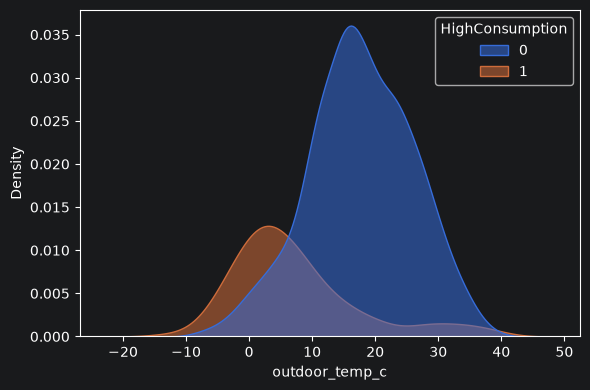

In [305]:
# KDE prikaz raspodele spoljne temperature odvojeno za domaćinstva sa visokom i ostalom potrošnjom.

plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='outdoor_temp_c',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()

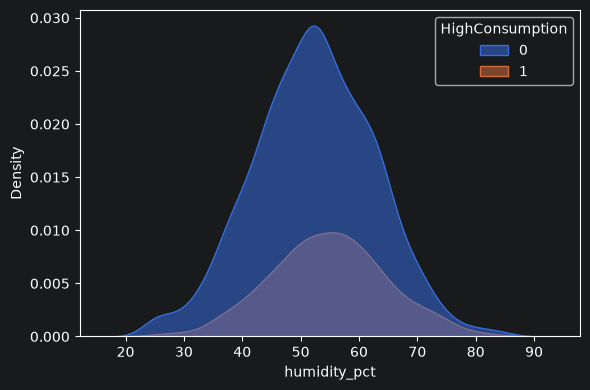

In [306]:
# Poređenje raspodele vlažnosti po klasama, a zatim uklanjanje te kolone iz prediktora.
# Sam vizuelni prikaz nije dovoljan dokaz da promenljiva nema prediktivnu vrednost.

plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='humidity_pct',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()
df.drop(columns='humidity_pct',inplace=True)

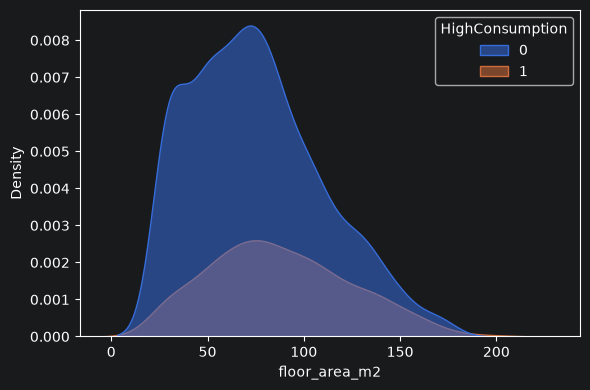

In [307]:
# Poređenje površine domaćinstava po klasama i uklanjanje površine iz daljeg modelovanja.

plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='floor_area_m2',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()
df.drop(columns='floor_area_m2',inplace=True)

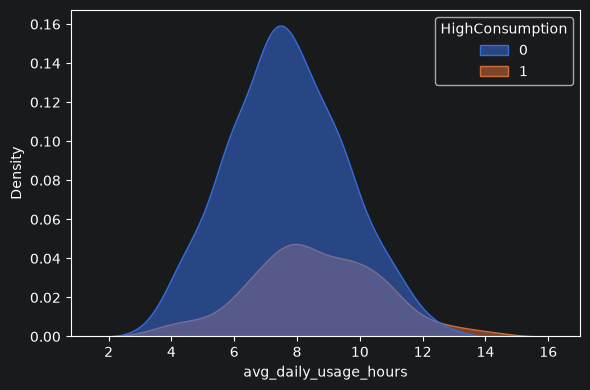

In [308]:
# Poređenje prosečnog dnevnog trajanja korišćenja po klasama potrošnje.

plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='avg_daily_usage_hours',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()

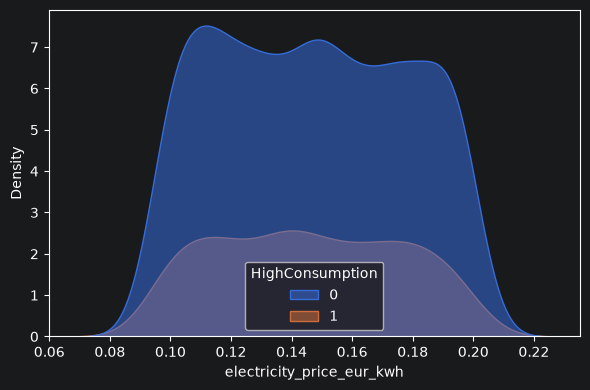

In [309]:
# Poređenje cene električne energije po klasama i uklanjanje te kolone iz prediktora.

plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='electricity_price_eur_kwh',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()

df.drop(columns='electricity_price_eur_kwh',inplace=True)

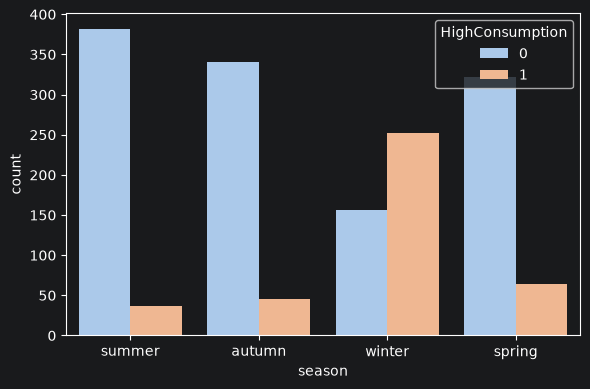

In [310]:
# Prikaz broja primera po godišnjim dobima, odvojeno prema klasi HighConsumption.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='season',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()

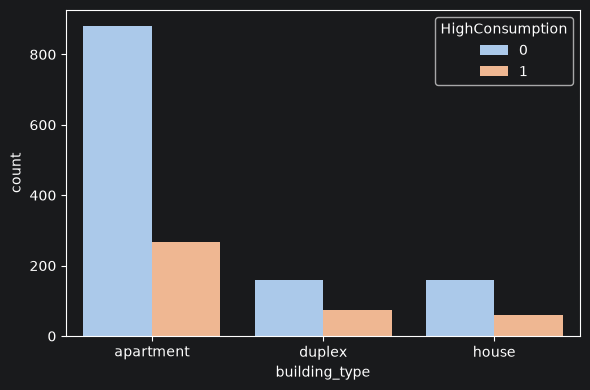

In [311]:
# Poređenje broja primera po tipu zgrade i klasi potrošnje.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='building_type',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()

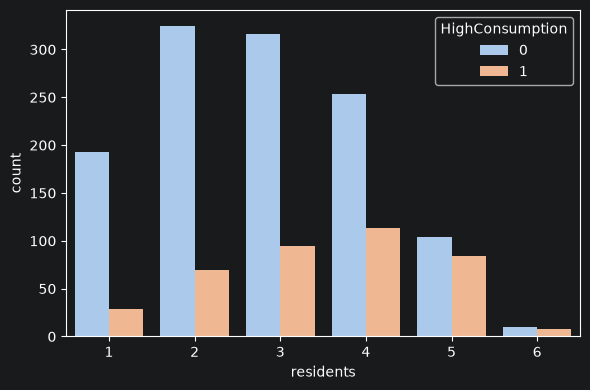

In [312]:
# Prikaz broja stanovnika domaćinstva u odnosu na klasu potrošnje.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='residents',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()



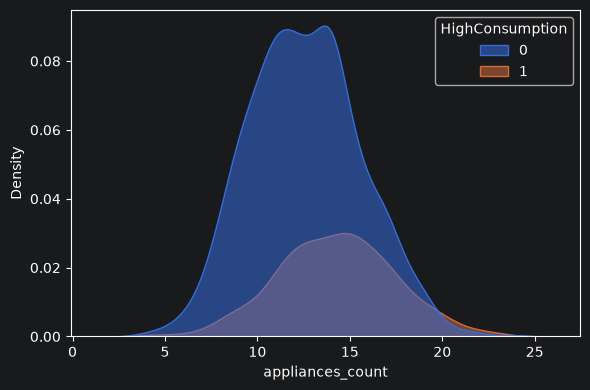

In [313]:
# Poređenje raspodele broja uređaja po klasama potrošnje.


plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='appliances_count',hue='HighConsumption',alpha=0.55,fill=True)
plt.tight_layout()
plt.show()

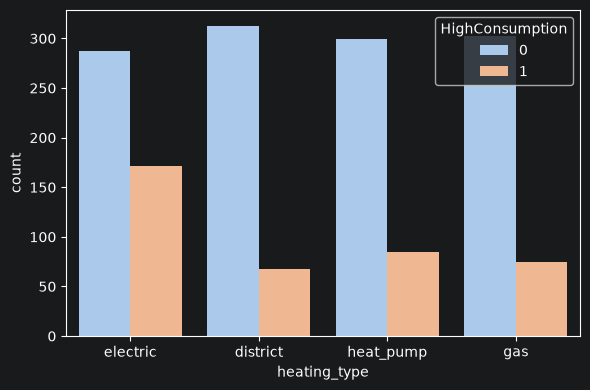

In [314]:
# Prikaz tipova grejanja odvojeno za dve klase potrošnje.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='heating_type',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()


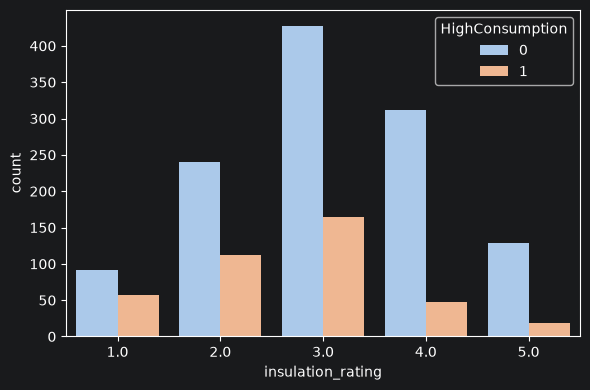

In [315]:
# Poređenje ocena izolacije domaćinstava po klasama.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='insulation_rating',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()

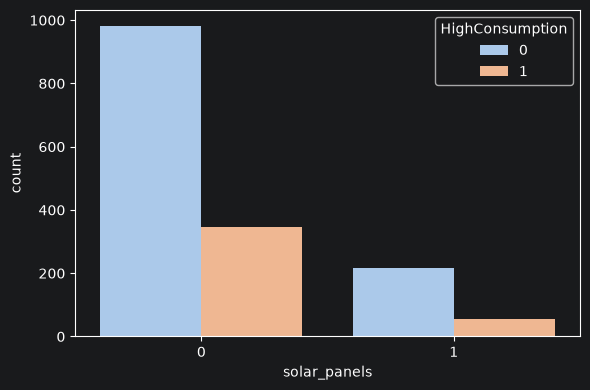

In [316]:
# Poređenje domaćinstava sa solarnim panelima i bez njih prema klasi potrošnje.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='solar_panels',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()

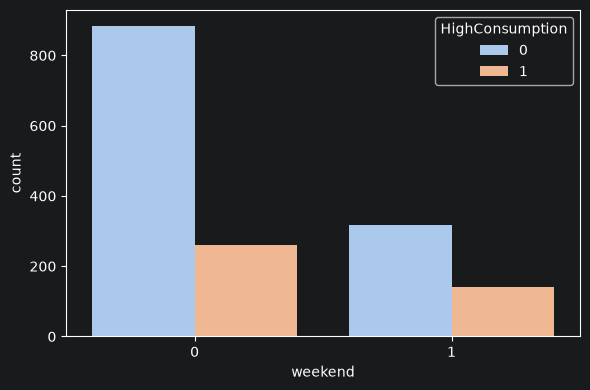

In [317]:
# Prikaz klasa potrošnje prema oznaci vikenda.

plt.figure(figsize=(6,4))
sns.countplot(data=df,x='weekend',hue='HighConsumption',palette='pastel')
plt.tight_layout()
plt.show()

In [318]:
# Brojanje potencijalnih ekstremnih vrednosti u izabranim numeričkim kolonama.
# IQR pravilo koristi granice Q1 - 1,5*IQR i Q3 + 1,5*IQR; ovde se vrednosti samo broje, ne uklanjaju.

num_varij=['outdoor_temp_c',
    'residents',
    'appliances_count',
    'insulation_rating',
    'avg_daily_usage_hours']
def brojac_out(variable):
    q1=variable.quantile(0.25)
    q3=variable.quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    return ((variable<lower)|(variable>upper)).sum()

for col in num_varij:
    print(f'broj out kolone {col} je {brojac_out(df[col])}')

broj out kolone outdoor_temp_c je 1
broj out kolone residents je 0
broj out kolone appliances_count je 11
broj out kolone insulation_rating je 0
broj out kolone avg_daily_usage_hours je 6


In [319]:
# Skaliranje numeričkih prediktora pomoću medijane i interkvartilnog raspona (RobustScaler).
# Skaliranje je važno jer kNN određuje susede na osnovu rastojanja.
# Dodavanje ciljne klase i binarnih prediktora uz očuvanje indeksa.
# Napomena: scaler se ovde uči na celom skupu; za nepristrasnu evaluaciju koristiti trening podatke i Pipeline.

from sklearn.preprocessing import RobustScaler
ro=RobustScaler()
data=ro.fit_transform(df[num_varij])
df_ro=pd.DataFrame(data,columns=num_varij,index=df.index)
df_ro['HighConsumption']=df['HighConsumption']

display(df_ro.head(5))

df_ro['solar_panels'] = df['solar_panels']
df_ro['weekend'] = df['weekend']

,outdoor_temp_c,residents,appliances_count,insulation_rating,avg_daily_usage_hours,HighConsumption
0,0.000000,-1.0,-1.00,0.0,0.000000,0
1,1.377622,0.0,-0.50,0.0,0.111111,0
2,1.356643,1.0,1.50,-0.5,0.888889,1
3,0.678322,0.5,1.00,0.0,-0.925926,0
4,1.146853,0.5,-0.25,-0.5,0.259259,1


In [320]:
# Kodiranje godišnjih doba brojevima od 0 do 3.
# Ovo uvodi numerička rastojanja između sezona; za kNN razmotriti one-hot ili ciklično kodiranje.

df['season'].unique()
df['season']=df['season'].map({'spring':0,'summer':1,'autumn':2,'winter':3})

In [321]:
# Pregled tekstualnih kolona i broja jedinstvenih vrednosti kategorijskih promenljivih.

df.select_dtypes(include='str').info()
for col in ['season','building_type','heating_type']:
    print(f'broj jedinstvenih vrednosti {col} je {df[col].nunique()}')

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   building_type  1600 non-null   str  
 1   heating_type   1600 non-null   str  
dtypes: str(2)
memory usage: 25.1 KB
broj jedinstvenih vrednosti season je 4
broj jedinstvenih vrednosti building_type je 3
broj jedinstvenih vrednosti heating_type je 4


In [322]:
# One-hot kodiranje tipa zgrade i grejanja uz zadržavanje svih kategorija.
# Dodavanje kodiranih kolona i sezone u tabelu skaliranih prediktora.
# Za buduće unapređenje: encoder učiti unutar trening dela validacije i njime transformisati test podatke.

from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False,drop=None)
cats=['building_type','heating_type']
encoded_array=ohe.fit_transform(df[cats])
encoded_col=ohe.get_feature_names_out(cats)
df_ohe=pd.DataFrame(encoded_array,columns=encoded_col,index=df.index)
df=df.drop(columns=cats).join(df_ohe)

df_ro['building_type_apartment']=df['building_type_apartment']
df_ro['building_type_duplex']=df['building_type_duplex']
df_ro['building_type_house']=df['building_type_house']

df_ro['heating_type_district']=df['heating_type_district']
df_ro['heating_type_gas']=df['heating_type_gas']
df_ro['heating_type_electric']=df['heating_type_electric']
df_ro['heating_type_heat_pump']=df['heating_type_heat_pump']

df_ro['season']=df['season']
display(df_ro.head(5))

,outdoor_temp_c,residents,appliances_count,insulation_rating,avg_daily_usage_hours,HighConsumption,solar_panels,weekend,building_type_apartment,building_type_duplex,building_type_house,heating_type_district,heating_type_gas,heating_type_electric,heating_type_heat_pump,season
0,0.000000,-1.0,-1.00,0.0,0.000000,0,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1
1,1.377622,0.0,-0.50,0.0,0.111111,0,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1
2,1.356643,1.0,1.50,-0.5,0.888889,1,0,0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
3,0.678322,0.5,1.00,0.0,-0.925926,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,2
4,1.146853,0.5,-0.25,-0.5,0.259259,1,0,1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1


In [323]:
# Razdvajanje prediktora X i ciljne promenljive y.
# Podela na 80% trening i 20% test podataka; stratify čuva približan udeo klasa.
# random_state=123 omogućava ponovljivu podelu.

X=df_ro.drop(columns='HighConsumption')
y=df_ro['HighConsumption']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=123,stratify=y)

In [324]:
# Pretraga neparnih vrednosti broja suseda od 3 do 25 pomoću desetostruke unakrsne validacije.
# Za ovaj klasifikator podrazumevana ocena je accuracy, a cv=10 koristi stratifikovane podele bez mešanja.
# n_jobs=-1 omogućava korišćenje svih dostupnih procesorskih jezgara.

param_grid={'n_neighbors':list(range(3,26,2))}
knn=KNeighborsClassifier()

grid=GridSearchCV(estimator=knn,
                  param_grid=param_grid,
                  cv=10,
                  verbose=1,
                  n_jobs=-1)
grid.fit(X_train,y_train)

best=grid.best_params_['n_neighbors']
print(best)

Fitting 10 folds for each of 12 candidates, totalling 120 fits
15


In [325]:
# Obučavanje kNN modela sa izabranim brojem suseda na trening skupu.
# Predviđanje klase visoke potrošnje za primere iz test skupa.

knn=KNeighborsClassifier(n_neighbors=best)
knn.fit(X_train,y_train)

y_pred=knn.predict(X_test)

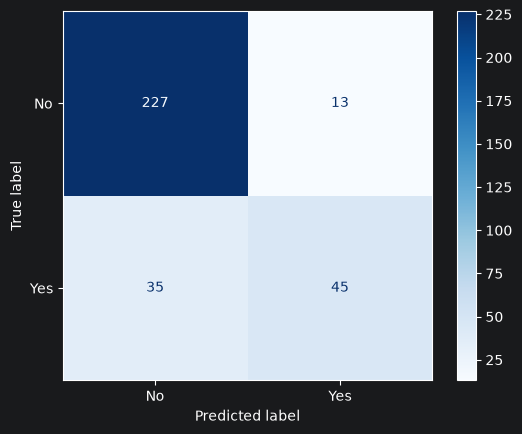

In [326]:
# Matrica konfuzije poredi stvarne klase (redovi) sa predviđenim klasama (kolone).
# No označava HighConsumption=0, a Yes HighConsumption=1.

from sklearn.metrics import ConfusionMatrixDisplay
cm_knn = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn,
                              display_labels=['No', 'Yes'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [327]:
# Funkcija za računanje tačnosti, preciznosti, odziva i F1 mere.
# Pozitivna klasa 1 predstavlja domaćinstva sa visokom potrošnjom.

def compute_eval_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=1)
    recall = recall_score(y_true, y_pred, pos_label=1)
    f1 = f1_score(y_true, y_pred, pos_label=1)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [328]:
# Izračunavanje i prikaz evaluacionih mera na test skupu.

eval=compute_eval_metrics(y_test,y_pred)
eval

{'accuracy': 0.85,
 'precision': 0.7758620689655172,
 'recall': 0.5625,
 'f1': 0.6521739130434783}